## 1.回归分析实验报告



导入相关模块 → pandas 数据加载 → 数据预处理（离散型数据转换、基本信息查看、空值判断）→ 构建一元回归模型 → 构建二元回归模型 → 构建多元回归模型

In [1]:
# 导入需要的包
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, train_test_split

## 2、数据加载

使用Python的pandas模块进行数据加载：

In [2]:
#通过pd.read_csv（）读取数据
df = pd.read_csv('../data/insurance.csv',header=0)
df.head(11)

,index,age,sex,bmi,children,smoker,region,charges
0,0,19,female,27.900,0,yes,southwest,16884.92400
1,1,18,male,33.770,1,no,southeast,1725.55230
2,2,28,male,33.000,3,no,southeast,4449.46200
3,3,33,male,22.705,0,no,northwest,21984.47061
4,4,32,male,28.880,0,no,northwest,3866.85520
5,5,31,female,25.740,0,no,southeast,3756.62160
6,6,46,female,33.440,1,no,southeast,8240.58960
7,7,37,female,27.740,3,no,northwest,7281.50560
8,8,37,male,29.830,2,no,northeast,6406.41070
9,9,60,female,25.840,0,no,northwest,28923.13692


### 字段说明

- **age**: 年龄
- **sex**: 男性或女性
- **bmi**: 人体重量指数
- **children**: 子女数量
- **smoker**: 是否抽烟
- **region**: 属于美国的哪个区域：NW,NE,SW,SE
- **charges**: 每年保险费用（美元）

## 3、数据预处理

Pandas对离散型数据进行转换的方法：

- map()
- apply()
- applymap()

### （1）替换sex和smoker列的字符串

In [3]:
# 使用map（）替换sex列的字符串
df['sex'] = df['sex'].map({'female':0,'male':1})
# 使用map（）替换smoker列的字符串
df['smoker'] = df['smoker'].map({'no':0,'yes':1})
df.head()

,index,age,sex,bmi,children,smoker,region,charges
0,0,19,0,27.900,0,1,southwest,16884.92400
1,1,18,1,33.770,1,0,southeast,1725.55230
2,2,28,1,33.000,3,0,southeast,4449.46200
3,3,33,1,22.705,0,0,northwest,21984.47061
4,4,32,1,28.880,0,0,northwest,3866.85520


### （2）替换region列的字符串

In [4]:
# 查看多少个区域
set(df['region'].to_list())

{'northeast', 'northwest', 'southeast', 'southwest'}

In [5]:
# 使用map（）替换region列的字符串
df['region'] = df['region'].map({'northeast':0,'northwest':1,'southeast':2,'southwest':3})
df.head(10)

,index,age,sex,bmi,children,smoker,region,charges
0,0,19,0,27.900,0,1,3,16884.92400
1,1,18,1,33.770,1,0,2,1725.55230
2,2,28,1,33.000,3,0,2,4449.46200
3,3,33,1,22.705,0,0,1,21984.47061
4,4,32,1,28.880,0,0,1,3866.85520
5,5,31,0,25.740,0,0,2,3756.62160
6,6,46,0,33.440,1,0,2,8240.58960
7,7,37,0,27.740,3,0,1,7281.50560
8,8,37,1,29.830,2,0,0,6406.41070
9,9,60,0,25.840,0,0,1,28923.13692


### （2续）使用apply（）改写字符串转换（与 map 等价，map 版本保留）

`apply()` 按元素作用在 Series 上，配合 lambda 条件表达式可实现与 `map()` 字典映射相同的编码。重新载入一份原始数据演示，避免在已编码的列上二次转换。

In [6]:
# 重新载入原始数据，演示 apply（）写法
df_apply = pd.read_csv('../data/insurance.csv',header=0)

# 使用apply（）+lambda 替换sex列的字符串
df_apply['sex'] = df_apply['sex'].apply(lambda x:1 if x=='male' else 0)
# 使用apply（）+lambda 替换smoker列的字符串
df_apply['smoker'] = df_apply['smoker'].apply(lambda x:1 if x=='yes' else 0)
# 使用apply（）+lambda 替换region列的字符串
df_apply['region'] = df_apply['region'].apply(lambda x:{'northeast':0,'northwest':1,'southeast':2,'southwest':3}[x])
df_apply.head()

,index,age,sex,bmi,children,smoker,region,charges
0,0,19,0,27.900,0,1,3,16884.92400
1,1,18,1,33.770,1,0,2,1725.55230
2,2,28,1,33.000,3,0,2,4449.46200
3,3,33,1,22.705,0,0,1,21984.47061
4,4,32,1,28.880,0,0,1,3866.85520


In [7]:
# 验证 apply（）结果与 map（）结果完全一致
(df_apply[['sex','smoker','region']].values == df[['sex','smoker','region']].values).all()

True

### （3）查看数据基本信息

In [8]:
# 查看数据基本信息
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   index     1338 non-null   int64  
 1   age       1338 non-null   int64  
 2   sex       1338 non-null   int64  
 3   bmi       1338 non-null   float64
 4   children  1338 non-null   int64  
 5   smoker    1338 non-null   int64  
 6   region    1338 non-null   int64  
 7   charges   1338 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 83.8 KB


### （4）判断是否有空值

In [9]:
# 判断是否有空值
df.isna().sum()

index       0
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

## 4、构建一元回归模型

保险费用（Charges）与是否吸烟（Smoker）存在很强的正相关性，我们构建一元线性回归模型

In [10]:
# 获取特征数据和标签数据
X = df[['smoker']]
Y = df[['charges']]

# 实例化模型
lr = LinearRegression()

# 训练模型
lr.fit(X,Y)

# 评估模型
lr.score(X,Y)

0.6197648148218988

Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
ipykernel_22360\76929028.py:5: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  plt.plot(xx,lr.predict(xx),'r-',lw=2,label='fit: y=%.0fx+%.0f'%(lr.coef_[0][0],lr.intercept_))


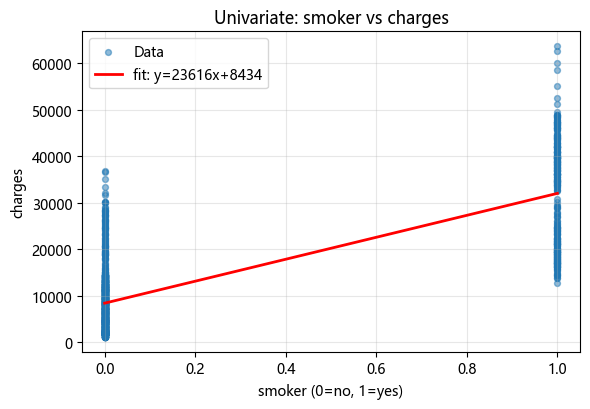

In [11]:
#画图：一元回归 smoker vs charges 散点图与拟合直线
plt.figure(figsize=(6,4.2))
plt.scatter(X,Y,alpha=0.5,s=18,label='Data')
xx = np.array([[0],[1]])
plt.plot(xx,lr.predict(xx),'r-',lw=2,label='fit: y=%.0fx+%.0f'%(lr.coef_[0][0],lr.intercept_))
plt.xlabel('smoker (0=no, 1=yes)')
plt.ylabel('charges')
plt.title('Univariate: smoker vs charges')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5、构建二元回归模型

为了使模型更精确，我们可以构建基于Age,Smoker与Charges之间构建二元回归模型

In [12]:
# 获取特征数据和标签数据
X1 = df[['age','smoker']]
Y1 = df[['charges']]

# 实例化模型
lr1 = LinearRegression()

# 训练模型
lr1.fit(X1,Y1)

# 评估模型
lr1.score(X1,Y1)

0.7214008260577199

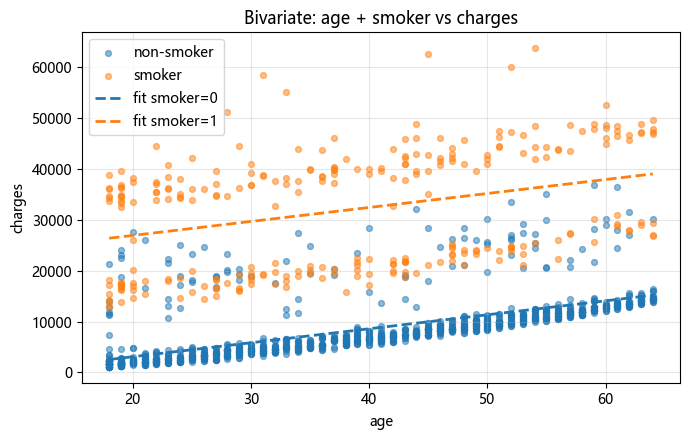

In [13]:
#画图：二元回归 age vs charges，按是否吸烟分组散点 + 两条拟合线
plt.figure(figsize=(7,4.5))
plt.scatter(df[df['smoker']==0]['age'],df[df['smoker']==0]['charges'],s=18,alpha=0.5,label='non-smoker')
plt.scatter(df[df['smoker']==1]['age'],df[df['smoker']==1]['charges'],s=18,alpha=0.5,label='smoker')
ages = np.linspace(df['age'].min(),df['age'].max(),100)
for s in [0,1]:
    plt.plot(ages,lr1.predict(pd.DataFrame({'age':ages,'smoker':[s]*100})),'--',lw=2,label='fit smoker=%d'%s)
plt.xlabel('age')
plt.ylabel('charges')
plt.title('Bivariate: age + smoker vs charges')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6、构建多元回归模型

为了使模型更精确，我们Charges设为标签，其他列设为特征，构建多元回归模型

In [14]:
# 切分数据集
y_data = df['charges']
x_data=df.drop('charges',axis=1)
x_train, x_test, y_train, y_test = train_test_split(x_data, y_data, test_size=0.20, random_state=1)

# 实例化模型
lr2 = LinearRegression()

# 训练模型
lr2.fit(x_train,y_train)

# 评估模型
lr2.score(x_test,y_test)

0.7624223827359452

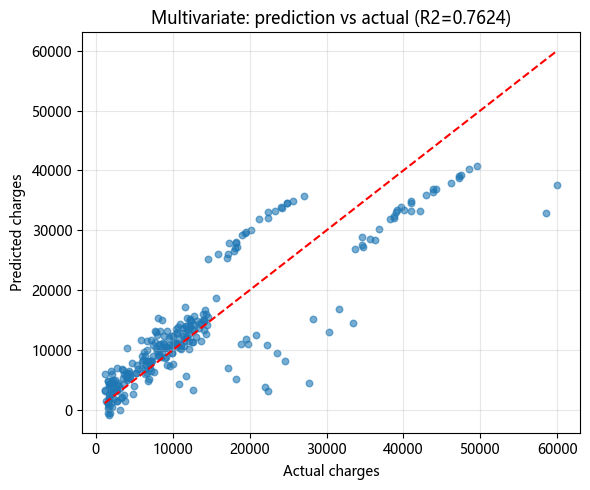

In [15]:
#画图：多元回归 测试集预测值 vs 真实值，越贴近对角线预测越准
y_pred = lr2.predict(x_test)

plt.figure(figsize=(6,5))
plt.scatter(y_test,y_pred,alpha=0.6,s=22)
lim = [y_test.min(),y_test.max()]
plt.plot(lim,lim,'r--',lw=1.5)
plt.xlabel('Actual charges')
plt.ylabel('Predicted charges')
plt.title('Multivariate: prediction vs actual (R2=%.4f)'%lr2.score(x_test,y_test))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

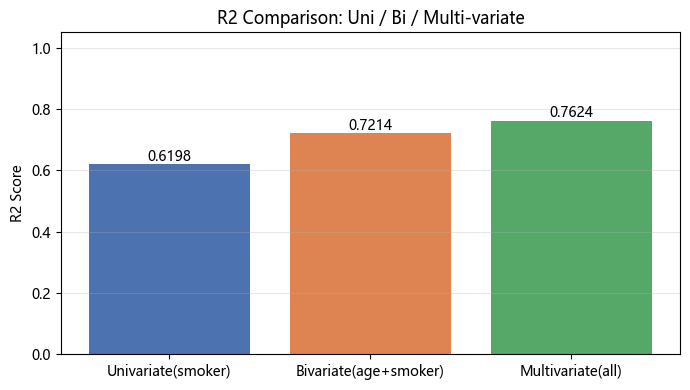

In [16]:
#画图：一元/二元/多元 R2 对比
models = ['Univariate(smoker)','Bivariate(age+smoker)','Multivariate(all)']
scores = [lr.score(X,Y),lr1.score(X1,Y1),lr2.score(x_test,y_test)]

plt.figure(figsize=(7,4))
bars = plt.bar(models,scores,color=['#4C72B0','#DD8452','#55A868'])
plt.ylim(0,1.05)
plt.ylabel('R2 Score')
plt.title('R2 Comparison: Uni / Bi / Multi-variate')
for b,s in zip(bars,scores):
    plt.text(b.get_x()+b.get_width()/2,s+0.01,format(s,'.4f'),ha='center')
plt.grid(axis='y',alpha=0.3)
plt.tight_layout()
plt.show()

## 7、实验总结

| 模型 | 特征 | 评估方式 | R² |
| --- | --- | --- | --- |
| 一元回归 | smoker | 训练集 | ≈0.62 |
| 二元回归 | age, smoker | 训练集 | ≈0.72 |
| 多元回归 | 除 charges 外全部列 | 测试集（8:2 划分） | ≈0.76 |

1. **数据预处理**：sklearn 回归模型只能接受数值特征，课件使用 `df.loc[]` 条件替换和 `apply()`+自定义函数（`str_int`）对 `sex`、`smoker`、`region` 三个离散型字符串列做标签编码，转换为整数；`df.info()` 确认转换后各列均为数值类型，`df.isna().sum()` 确认无空值，无需缺失值处理。
2. **特征越多，拟合越好**：从一元（仅 smoker）到二元（age+smoker）再到多元（全部特征），R² 由 0.62 逐步提升到 0.76，说明是否吸烟是最主要的单一驱动因素，年龄、BMI 等提供了增量信息。
3. **评估口径的变化**：一元、二元模型直接在训练集上 `score()`，多元模型先 `train_test_split` 切分再在**测试集**上评分，后者更能反映模型的泛化能力，是更规范的评估方式。

不改任何东西，就用 0919 里那段多元回归代码，大白话讲一遍。

啥是多元拟合

一元拟合是"一个原因猜一个结果"：比如只看是否吸烟猜保费。多元拟合就是同时看好几个原因猜结果：吸烟、年龄、BMI、性别、地区……一起上，让模型自己学出一套"加权公式"：

保费 ≈ w1×吸烟 + w2×年龄 + w3×BMI + ... + b

模型的活儿就是把每个 w（权重/系数）调得让算出来的数和真实保费尽量接近。哪个因素重要，它的 w 就大。

代码逐行大白话

y_data = df['charges']          # 答案：要预测的东西（保费），单独拎出来
x_data = df.drop('charges',axis=1)  # 题目：除了保费外的所有列，都当线索
就像做题：x_data 是试卷上的已知条件，y_data 是标准答案。axis=1 意思是"删掉这一列"。

x_train, x_test, y_train, y_test = train_test_split(x_data, y_data, test_size=0.20, random_state=1)
把 1338 条数据随机切成两堆：80% 当"平时练习题"（训练集），20% 当"期末考卷"（测试集）。
模型只用练习题学习，从没见过考卷的答案；
random_state=1 是"洗牌种子"，固定它每次切出来的卷子的方一样，结果可复现。

lr2 = LinearRegression()   # 实例化：请出一个"线性回归"学生，此时他还没学
lr2.fit(x_train, y_train)  # 训练：给他练习题和答案，他自己悟出各个 w 和 b
fit 之后模型内部就记下了那套权重，相当于背下了公式。

lr2.score(x_test, y_test)  # 评估：拿考卷测他
把考卷的题目（x_test）喂给模型算预测值，再和考卷答案（y_test）对比，输出 R² 分数。R²=0.76 可以粗略理解成：保费的差异里，约 76% 能被这几个因素"解释"，剩下 24% 是模型抓不到的（个体差异、随机波动等）。

为什么这样比一元/二元那两步更规范

前面一元、二元是 lr.score(X,Y)——用练习题本身考试，学生可能死记硬背也拿高分（过拟合），分数虚高。多元这步是用没见过的题考试，考出来的才是真实水平。这也是为什么 0914 里花那么大篇幅讲过拟合：训练集分数越完美，越要留个心眼。